# Task 4: Game Title Detection EDA

Image classification EDA using only supplied files. No pretrained model is loaded or trained.

## 1. Dataset Loading

In [11]:
import warnings
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

warnings.filterwarnings('ignore')
SEED = 342
sns.set_theme(style='whitegrid', context='notebook')

# Locate the supplied Task 4 directory instead of assuming a fixed absolute path.
PROJECT_ROOT = Path('..')
task_dirs = [d for d in PROJECT_ROOT.rglob('*') if d.is_dir() and (d / 'train.csv').is_file() and (d / 'test.csv').is_file() and (d / 'train').is_dir() and (d / 'test').is_dir()]
if not task_dirs:
    raise FileNotFoundError('Could not locate a directory containing train.csv, test.csv, train/, and test/.')
TASK4_DIR = task_dirs[0]
TRAIN_DIR, TEST_DIR = TASK4_DIR / 'train', TASK4_DIR / 'test'
train, test = pd.read_csv(TASK4_DIR / 'train.csv'), pd.read_csv(TASK4_DIR / 'test.csv')
label_col = 'game_title' if 'game_title' in train.columns else 'class'
print('Located Task 4 directory:', TASK4_DIR)
print('Train shape:', train.shape, '| Test shape:', test.shape)
display(train.head())
display(pd.DataFrame({'train_dtype': train.dtypes, 'test_dtype': test.dtypes}))


Located Task 4 directory: ../cpe342-kaggle-main/04_image_classification
Train shape: (31546, 2) | Test shape: (25889, 2)


,id,class
0,su7tkav,7-11k
1,shlk51f,roblock
2,sbdqvs0,7-11k
3,s6oe1m9,freefried
4,skn51jb,7-11k


,train_dtype,test_dtype
id,str,str
class,str,float64


## 2. Dataset Overview & CSV Quality

In [12]:
display(train.describe(include='all').T)
print('Train missing values:', train.isna().sum().to_dict())
print('Test missing values:', test.isna().sum().to_dict())
print('Duplicate train IDs:', train.id.duplicated().sum(), '| duplicate test IDs:', test.id.duplicated().sum())
print('Train/test ID overlap:', len(set(train.id) & set(test.id)))
train_paths = {x.stem: x for x in TRAIN_DIR.glob('*') if x.suffix.lower() in {'.jpg','.jpeg','.png','.webp'}}
test_paths = {x.stem: x for x in TEST_DIR.glob('*') if x.suffix.lower() in {'.jpg','.jpeg','.png','.webp'}}
missing_train = sorted(set(train.id.astype(str)) - set(train_paths))
missing_test = sorted(set(test.id.astype(str)) - set(test_paths))
print('CSV references without accessible image:', len(missing_train), 'train and', len(missing_test), 'test')
print('Unreferenced images:', len(set(train_paths)-set(train.id.astype(str))), 'train and', len(set(test_paths)-set(test.id.astype(str))), 'test')


,count,unique,top,freq
id,31546,31546,su7tkav,1
class,31546,5,7-11k,12429


Train missing values: {'id': 0, 'class': 0}
Test missing values: {'id': 0, 'class': 25889}
Duplicate train IDs: 0 | duplicate test IDs: 0
Train/test ID overlap: 0
CSV references without accessible image: 0 train and 0 test
Unreferenced images: 0 train and 0 test


## 3. Class Distribution

,count,percent
class,,
7-11k,12429,39.40
fiveN,4407,13.97
freefried,5596,17.74
pube,5926,18.79
roblock,3188,10.11


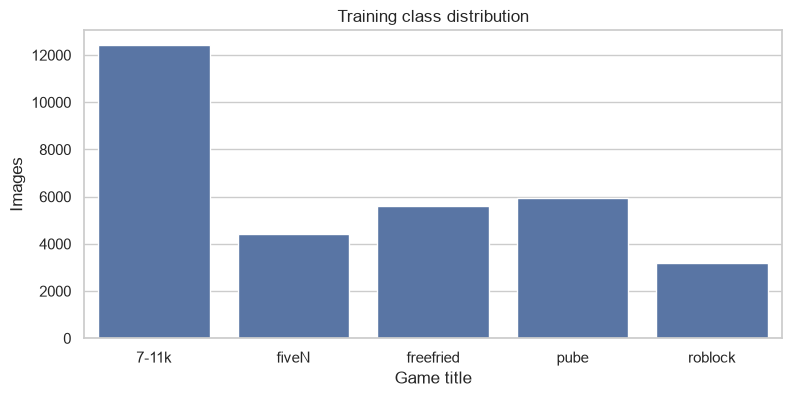

In [13]:
class_counts = train[label_col].value_counts().sort_index()
class_summary = pd.DataFrame({'count': class_counts, 'percent': class_counts.div(len(train)).mul(100).round(2)})
display(class_summary)
fig, ax = plt.subplots(figsize=(9,4))
sns.barplot(x=class_summary.index, y='count', data=class_summary.reset_index(), color='#4C72B0', ax=ax)
ax.set(title='Training class distribution', xlabel='Game title', ylabel='Images')
plt.show(); plt.close()


## 4. Locate Image Dependencies

In [14]:
# Inspect one file at a time; no image pixel arrays are retained.
def inspect_file(path, split):
    try:
        with Image.open(path) as image:
            image.verify()
        with Image.open(path) as image:
            return {'split': split, 'id': path.stem, 'path': str(path), 'format': image.format, 'mode': image.mode, 'width': image.width, 'height': image.height, 'aspect_ratio': image.width / image.height, 'bytes': path.stat().st_size, 'sha256': hashlib.sha256(path.read_bytes()).hexdigest(), 'error': None}
    except Exception as error:
        return {'split': split, 'id': path.stem, 'path': str(path), 'error': str(error)}

image_info = pd.DataFrame([inspect_file(path, 'train') for path in train_paths.values()] + [inspect_file(path, 'test') for path in test_paths.values()])
train_info = image_info.query("split == 'train'").merge(train[['id', label_col]], on='id', how='left')
print('Unreadable images:', image_info.error.notna().sum())
display(image_info.groupby(['split','format','mode']).agg(images=('id','count'), width_min=('width','min'), width_max=('width','max'), height_min=('height','min'), height_max=('height','max'), bytes_median=('bytes','median')))
display(train_info.groupby(label_col).agg(images=('id','count'), width_median=('width','median'), height_median=('height','median'), bytes_median=('bytes','median')))


Unreadable images: 0


,,,images,width_min,width_max,height_min,height_max,bytes_median
split,format,mode,,,,,,
test,JPEG,RGB,25889,230,230,120,120,10644.0
train,JPEG,RGB,31546,230,230,120,120,10770.5


,images,width_median,height_median,bytes_median
class,,,,
7-11k,12429,230.0,120.0,10876.0
fiveN,4407,230.0,120.0,10576.0
freefried,5596,230.0,120.0,10783.0
pube,5926,230.0,120.0,10716.0
roblock,3188,230.0,120.0,10700.5


## 5. Image Analysis (runs only when files are present)

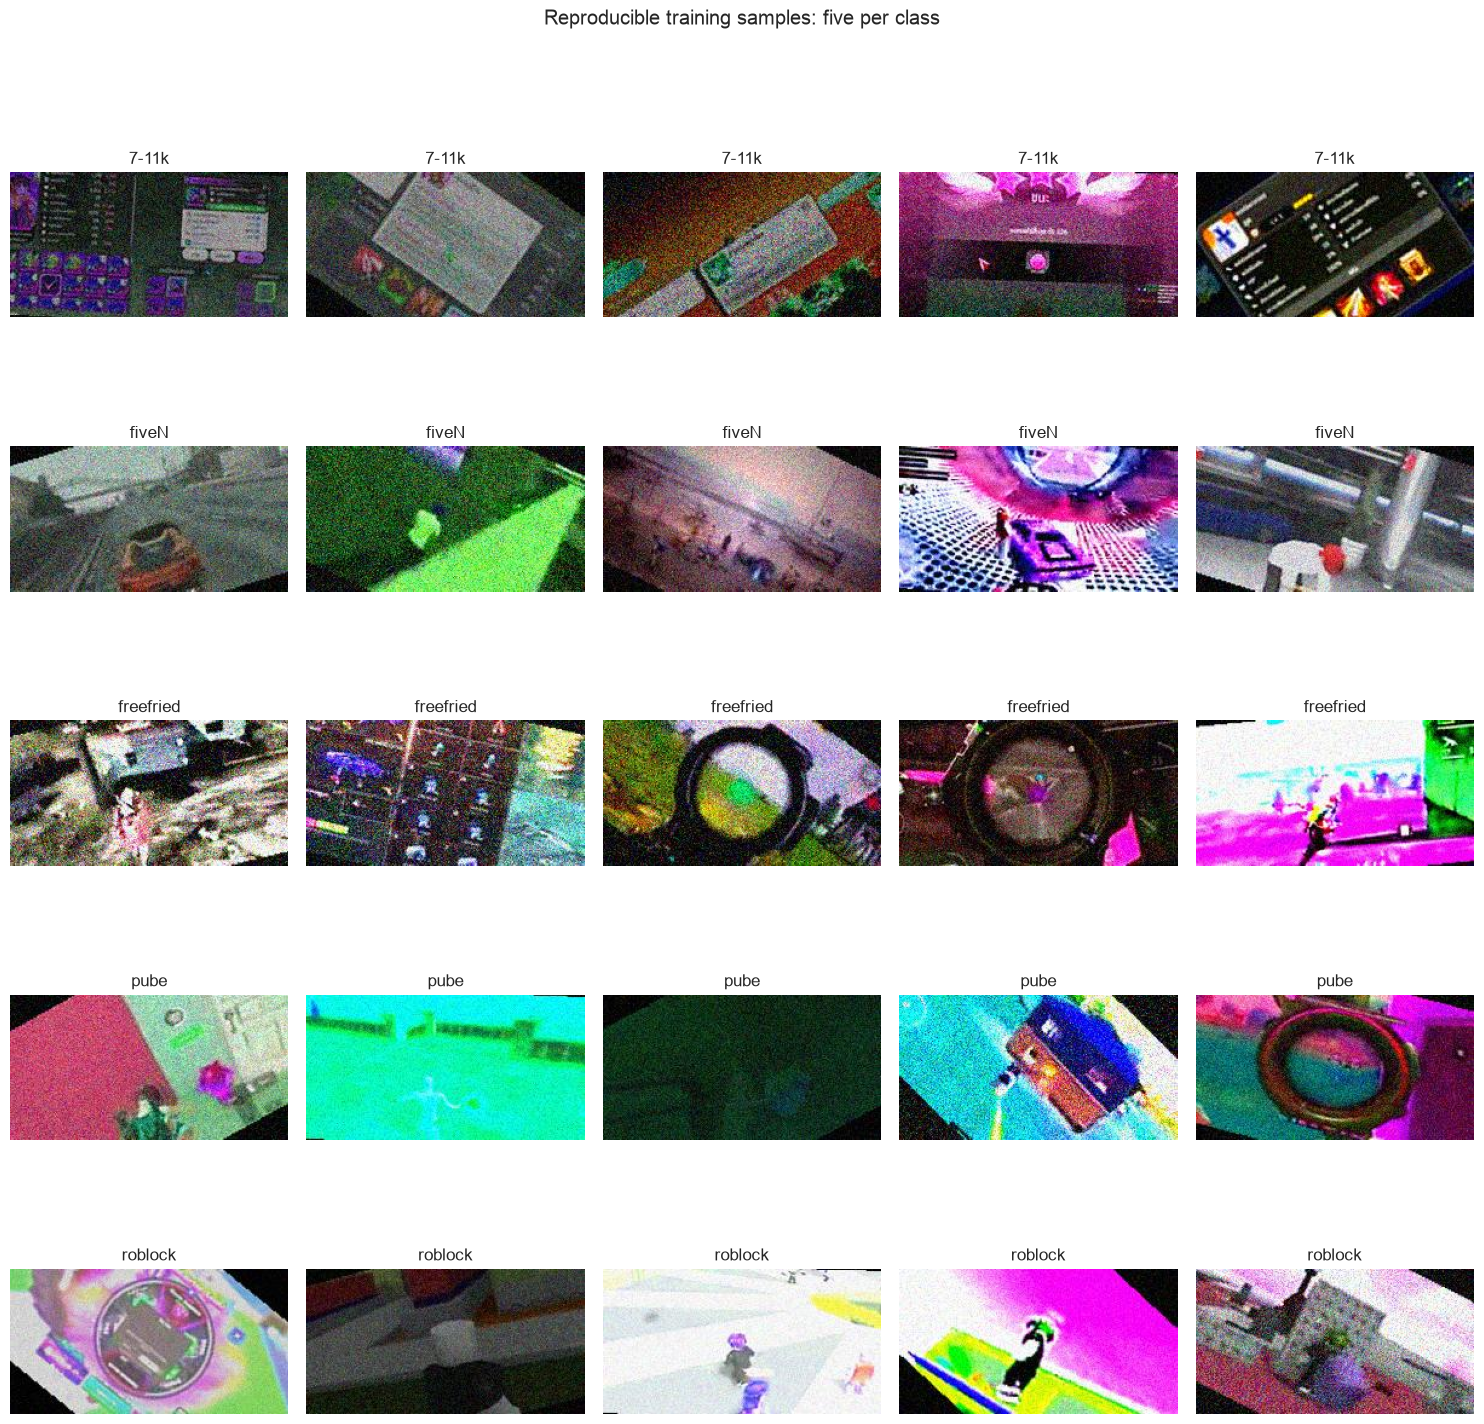

Duplicate hashes within all supplied images: 0
Exact train/test content overlap: 0


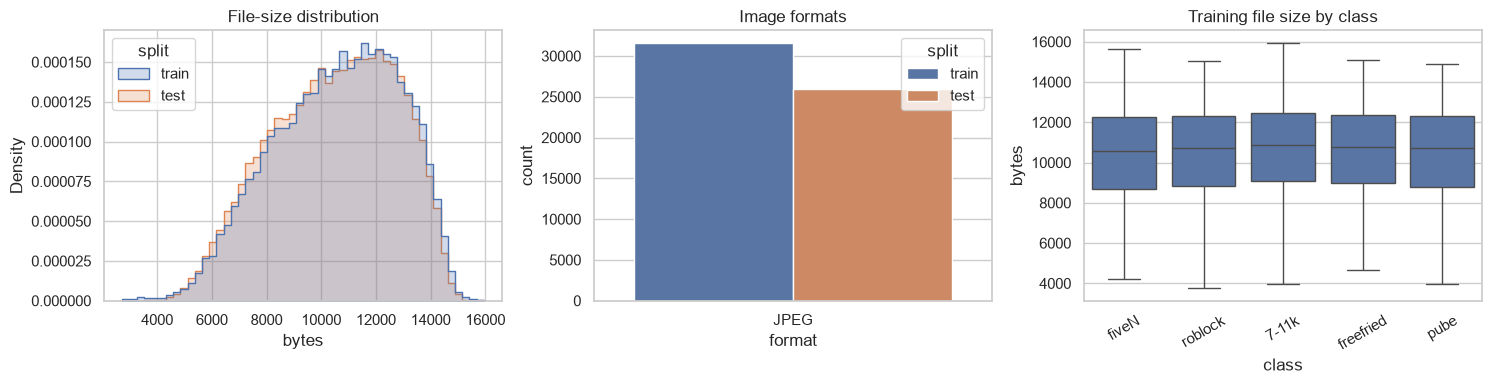

In [15]:
# Reproducible, labelled training samples only: five images per class.
fig, axes = plt.subplots(len(class_counts), 5, figsize=(15, 3 * len(class_counts)))
for row, (label, group) in enumerate(train.groupby(label_col, sort=True)):
    sample = group.sample(n=min(5, len(group)), random_state=SEED)
    for col, (_, record) in enumerate(sample.iterrows()):
        with Image.open(train_paths[str(record.id)]) as image:
            axes[row, col].imshow(image.convert('RGB'))
        axes[row, col].set_title(str(label))
        axes[row, col].axis('off')
plt.suptitle('Reproducible training samples: five per class', y=1.01)
plt.tight_layout(); plt.show(); plt.close()

train_hashes = set(image_info.query("split == 'train'").sha256.dropna())
test_hashes = set(image_info.query("split == 'test'").sha256.dropna())
print('Duplicate hashes within all supplied images:', image_info.sha256.duplicated().sum())
print('Exact train/test content overlap:', len(train_hashes & test_hashes))
fig, axes = plt.subplots(1, 3, figsize=(15,4))
sns.histplot(data=image_info, x='bytes', hue='split', bins=50, element='step', stat='density', common_norm=False, ax=axes[0]); axes[0].set_title('File-size distribution')
sns.countplot(data=image_info, x='format', hue='split', ax=axes[1]); axes[1].set_title('Image formats')
sns.boxplot(data=train_info, x=label_col, y='bytes', showfliers=False, ax=axes[2]); axes[2].set_title('Training file size by class'); axes[2].tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show(); plt.close()


## EDA Summary & Recommendations

### Key findings

- The tables above report the actual class counts and percentages, CSV-to-image mapping, image dimensions, formats, file sizes, unreadable files, and content hashes.
- Macro F1 gives each game equal weight, so the smaller classes must be represented in future validation folds; raw accuracy could conceal weak performance for a minority game.
- Inspect the five fixed-seed samples per class before making visual claims. UI, text overlays, colour palettes, cropping, and compression can become shortcuts for a classifier; they should be treated as hypotheses until supported by repeated inspection.
- Exact SHA-256 hashes detect byte-identical images. A non-zero train/test overlap is a leakage risk and must be resolved before validation. No images are modified here.

### Recommendations

Use RGB decoding, a consistent resize/crop policy, and normalization chosen later within the training pipeline. Consider modest, game-appropriate augmentation such as horizontal flips only after checking that game UI text and directional cues are not harmed; avoid test images when fitting any preprocessing. Future image experiments can use stratified validation and pretrained backbones permitted by the course rules, while reporting Macro F1. This notebook trains and evaluates no model.
